# 신약 후보물질 독성 예측 — 도메인 기반 EDA (RDKit · 의약화학 규칙 · 구조 경고)

**목표:** 화합물 구조(SMILES)와 제공 피처(ECFP/FCFP/PTFP 각 1,024bit, MolWt·clogp·sa_score·qed)로 독성 여부를 분류하기 전에,
데이터를 **의약화학(medicinal chemistry) 관점**에서 탐색하고 모델링 전략에 반영할 근거를 찾는다.

| 항목 | 내용 |
|---|---|
| 데이터 | `train.csv` — 8,349행 × 3,078열 (과제 PDF p.12–13) |
| 타깃 | `label` — **1 = 독성 無 (Positive)**, **0 = 독성 有 (Negative)** |
| 과제 | 이진 분류, 이후 `predict_input.csv` 927건 예측 |
| 주의 | PDF p.11 *"Before modeling, always verify what the target label actually means."* → 이 노트북에서는 **독성률 = P(label = 0)** 으로 표기한다 |

### 이 노트북의 분석 질문
1. 제공된 fingerprint/descriptor는 **어떤 알고리즘으로 만들어졌는가?** (재현 가능해야 예측 데이터 전처리·해석이 가능)
2. 분자 물성(크기·지용성·극성) 중 무엇이 독성과 관련 있는가? 문헌의 경험 규칙(Lipinski, Veber, **Pfizer 3/75**)이 이 데이터에서도 성립하는가?
3. 알려진 **구조 경고(structural alert: Brenk, PAINS, NIH)** 와 작용기는 독성 라벨과 어떤 관계인가?
4. 독성과 가장 강하게 연관된 **fingerprint bit는 실제로 어떤 부분 구조**인가?
5. 골격(scaffold) 수준에서 데이터가 얼마나 다양하며, 검증 분할을 어떻게 해야 하는가?
6. 피처 묶음별로 예측 신호가 얼마나 되는가?

### 참고 자료 (인터넷 조사)
- Hughes et al. (2008), *Physiochemical drug properties associated with in vivo toxicological outcomes*, BMCL 18:4872 — **Pfizer 3/75 규칙**: clogP > 3 이고 TPSA < 75 Å² 인 화합물은 독성 소견 가능성이 약 2.5배 높음. 후속 검증: [PMC7025387](https://pmc.ncbi.nlm.nih.gov/articles/PMC7025387)
- Lipinski et al. (1997) Rule of Five / Veber et al. (2002) 경구 흡수 규칙
- Bickerton et al. (2012), *Quantifying the chemical beauty of drugs*, Nat. Chem. — **QED** (0~1, 8개 물성의 desirability 기하평균) [PubMed](https://pubmed.ncbi.nlm.nih.gov/22270643/)
- Ertl & Schuffenhauer (2009) — **SA score** (1 = 합성 쉬움 ~ 10 = 어려움)
- Brenk et al. (2008) 반응성/바람직하지 않은 부분 구조, Baell & Holloway (2010) **PAINS** — RDKit `FilterCatalog` 내장. 경고가 있다고 반드시 독성인 것은 아님 ([Chemical Probes Portal](https://www.chemicalprobes.org/info/pains))
- Rogers & Hahn (2010), *Extended-Connectivity Fingerprints* — ECFP/FCFP

## 0. 환경 설정

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors, QED, Draw
from rdkit.Chem import rdFingerprintGenerator as rfg
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")

# 한글 폰트 (macOS: AppleGothic, Windows: Malgun Gothic, Colab: NanumGothic 설치 필요)
for font in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if any(font in f.name for f in plt.matplotlib.font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font=plt.rcParams["font.family"][0] if isinstance(plt.rcParams["font.family"], list) else plt.rcParams["font.family"])

RANDOM_STATE = 42
PALETTE = {0: "#d1495b", 1: "#2e86ab"}           # 0 = 독성 有(빨강), 1 = 독성 無(파랑)
LABEL_NAME = {0: "독성 有 (0)", 1: "독성 無 (1)"}

## 1. 데이터 로드와 기본 점검

In [2]:
DATA_PATH = next(p for p in [Path("train.csv"), Path("/content/train.csv")] if p.exists())
header = pd.read_csv(DATA_PATH, nrows=0).columns
fp_cols = {k: [c for c in header if c.startswith(f"{k}_")] for k in ["ecfp", "fcfp", "ptfp"]}
desc_cols = ["MolWt", "clogp", "sa_score", "qed"]

dtypes = {c: "uint8" for cols in fp_cols.values() for c in cols}
df = pd.read_csv(DATA_PATH, dtype=dtypes)
df["toxic"] = (df["label"] == 0).astype(int)          # 해석 편의를 위한 보조 변수

print(f"shape: {df.shape},  메모리: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print({k: len(v) for k, v in fp_cols.items()})
print("결측 셀:", int(df.isna().sum().sum()), "| 중복 SMILES:", int(df["SMILES"].duplicated().sum()))
display(df[["SMILES", *desc_cols, "label"]].head())

shape: (8349, 3079),  메모리: 26.9 MB
{'ecfp': 1024, 'fcfp': 1024, 'ptfp': 1024}
결측 셀: 0 | 중복 SMILES: 0


,SMILES,MolWt,clogp,sa_score,qed,label
0,Nc1ccncc1,94.117,0.66380,1.951060,0.512651,1
1,Cc1cc(n[nH]1)C(=O)O,126.115,0.41632,2.373113,0.572518,1
2,NCCCS(=O)(=O)O,139.176,-0.77700,2.336083,0.502646,1
3,OC(=O)c1cc2occc2[nH]1,151.121,1.45910,2.624244,0.647854,1
4,CN1CCC[C@H]1c2cccnc2,162.236,1.84830,2.499926,0.626152,1


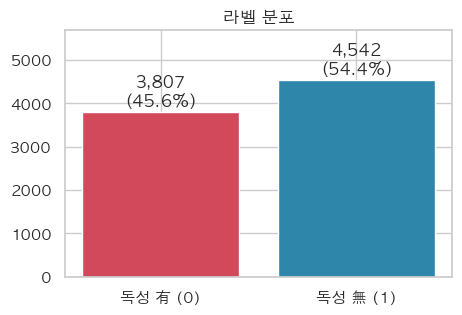

기저 독성률 P(label=0) = 0.456  → 약간 불균형(≈ 46:54), 리샘플링보다 stratify로 충분


In [3]:
counts = df["label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar([LABEL_NAME[i] for i in counts.index], counts.values, color=[PALETTE[i] for i in counts.index])
ax.bar_label(bars, labels=[f"{v:,}\n({v / len(df):.1%})" for v in counts.values], padding=2)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("라벨 분포")
plt.show()
BASE_TOX = df["toxic"].mean()
print(f"기저 독성률 P(label=0) = {BASE_TOX:.3f}  → 약간 불균형(≈ 46:54), 리샘플링보다 stratify로 충분")

## 2. 제공 피처의 생성 방법 역추적 (재현성 검증)

PDF에는 fingerprint 종류만 있고 반경·옵션은 없다. RDKit으로 여러 후보를 계산해 **전체 8,349건과 bit 단위로 완전 일치**하는 설정을 찾는다.
재현되면 ① `predict_input.csv`나 새 SMILES에도 동일 피처를 만들 수 있고 ② 각 bit가 **어떤 원자 환경인지 역해석**할 수 있다.

In [4]:
mols = df["SMILES"].map(Chem.MolFromSmiles)
print("RDKit 파싱 실패:", int(mols.isna().sum()))

def to_array(fp, n=1024):
    arr = np.zeros(n, dtype=np.uint8)
    arr[list(fp.GetOnBits())] = 1
    return arr

ecfp_gen = rfg.GetMorganGenerator(radius=2, fpSize=1024)
fcfp_gen = rfg.GetMorganGenerator(radius=2, fpSize=1024,
                                  atomInvariantsGenerator=rfg.GetMorganFeatureAtomInvGen())
candidates = {
    "ecfp": ("Morgan radius=2 (ECFP4), 1024bit", lambda m: ecfp_gen.GetFingerprint(m)),
    "fcfp": ("Morgan feature radius=2 (FCFP4), 1024bit", lambda m: fcfp_gen.GetFingerprint(m)),
    "ptfp": ("RDKit PatternFingerprint, 1024bit", lambda m: Chem.PatternFingerprint(m, 1024)),
}
rows = []
for key, (desc, fn) in candidates.items():
    recomputed = np.vstack([to_array(fn(m)) for m in mols])
    original = df[fp_cols[key]].to_numpy()
    rows.append({"블록": key.upper(), "재현 설정": desc,
                 "행 단위 완전일치율": (recomputed == original).all(axis=1).mean(),
                 "bit 단위 일치율": (recomputed == original).mean()})

recalc_desc = pd.DataFrame({
    "MolWt": mols.map(Descriptors.MolWt),
    "clogp": mols.map(Crippen.MolLogP),
    "qed": mols.map(QED.qed),
})
for c in recalc_desc:
    rows.append({"블록": c, "재현 설정": f"RDKit {c}",
                 "행 단위 완전일치율": np.isclose(recalc_desc[c], df[c], atol=1e-3).mean(),
                 "bit 단위 일치율": np.nan})
display(pd.DataFrame(rows).round(4))

RDKit 파싱 실패: 0


,블록,재현 설정,행 단위 완전일치율,bit 단위 일치율
0,ECFP,"Morgan radius=2 (ECFP4), 1024bit",0.9994,1.0
1,FCFP,"Morgan feature radius=2 (FCFP4), 1024bit",1.0000,1.0
2,PTFP,"RDKit PatternFingerprint, 1024bit",1.0000,1.0
3,MolWt,RDKit MolWt,1.0000,NaN
4,clogp,RDKit clogp,1.0000,NaN
5,qed,RDKit qed,0.9999,NaN


> **결과 해석:** FCFP = Morgan feature r=2 (FCFP4), PTFP = RDKit PatternFingerprint는 **8,349행 모두 완전 일치**, ECFP = Morgan r=2 (ECFP4)는 **99.94% 행 일치**(5행만 1~2bit 차이 — RDKit 버전 차이로 추정)이고, MolWt·clogp·qed도 RDKit 값과 같다 (sa_score는 RDKit Contrib `sascorer`로 계산된 것으로 보인다).
> 따라서 RDKit으로 **추가 descriptor를 만들어도 동일한 화학 표현 체계 위에서 확장**하는 것이며, 예측 데이터에도 같은 파이프라인을 적용할 수 있다.

## 3. 제공 descriptor 4종 — 라벨별 분포와 효과 크기

정규성을 가정하지 않는 **Mann–Whitney U 검정**과, 단일 변수의 분리 능력을 나타내는 **AUC**(0.5 = 무관, |AUC − 0.5| 클수록 분리)를 함께 본다.
표본이 커서 p-value는 거의 항상 작으므로 **효과 크기(AUC)** 를 중심으로 해석한다.

,feature,median_독성有,median_독성無,AUC(독성↑),|AUC-0.5|,p_value
0,clogp,4.1517,3.3676,0.6625,0.1625,0.0000
1,qed,0.5385,0.5707,0.4515,0.0485,0.0000
2,sa_score,3.0323,3.1426,0.4587,0.0413,0.0000
3,MolWt,440.9960,441.7475,0.5053,0.0053,0.3999


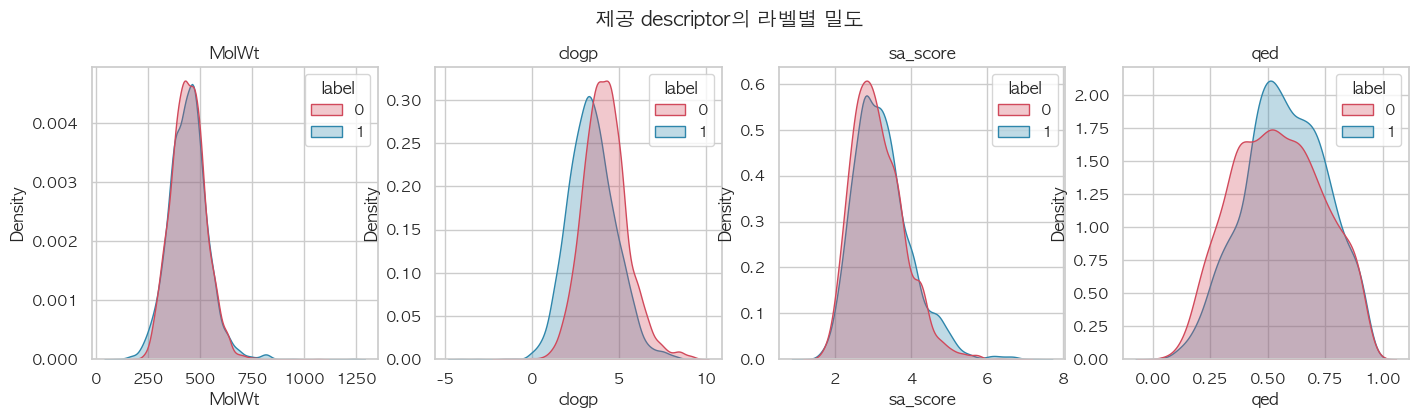

In [5]:
def univariate_table(frame, cols, target="toxic"):
    out = []
    pos, neg = frame[frame[target] == 1], frame[frame[target] == 0]
    for c in cols:
        u, p = stats.mannwhitneyu(pos[c], neg[c], alternative="two-sided")
        auc = u / (len(pos) * len(neg))                 # P(독성 화합물 값 > 비독성 화합물 값)
        out.append({"feature": c, "median_독성有": pos[c].median(), "median_독성無": neg[c].median(),
                    "AUC(독성↑)": auc, "|AUC-0.5|": abs(auc - 0.5), "p_value": p})
    return pd.DataFrame(out).sort_values("|AUC-0.5|", ascending=False).reset_index(drop=True)

display(univariate_table(df, desc_cols).round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, desc_cols):
    sns.kdeplot(data=df, x=c, hue="label", palette=PALETTE, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(c)
plt.suptitle("제공 descriptor의 라벨별 밀도", y=1.03)
plt.show()

- 독성 화합물은 **clogp(지용성)가 높은 쪽**으로 치우친다 (중앙값 4.15 vs 3.37, AUC 0.66). 지용성이 높을수록 막 투과·비특이 결합·대사 부담이 커져 독성 소견과 연결된다는 문헌(Hughes 2008)과 같은 방향이다.
- qed·sa_score는 독성 쪽이 약간 낮지만(AUC 0.45~0.46) 효과가 작고, **MolWt는 사실상 무관**(AUC 0.505, p = 0.40)하다. 단일 descriptor로는 분리가 어렵고 **구조 정보(fingerprint)가 핵심**일 것으로 예상된다.

## 4. RDKit 추가 descriptor 생성

Pfizer 3/75 규칙과 Lipinski·Veber 규칙에 필요한 **TPSA, HBD/HBA, 회전 가능 결합** 등은 제공 데이터에 없으므로 RDKit으로 계산한다.

In [6]:
def count_atoms(m, symbols):
    return sum(a.GetSymbol() in symbols for a in m.GetAtoms())

extra = pd.DataFrame({
    "TPSA": mols.map(rdMolDescriptors.CalcTPSA),
    "HBD": mols.map(rdMolDescriptors.CalcNumHBD),
    "HBA": mols.map(rdMolDescriptors.CalcNumHBA),
    "RotB": mols.map(rdMolDescriptors.CalcNumRotatableBonds),
    "HeavyAtoms": mols.map(lambda m: m.GetNumHeavyAtoms()),
    "Rings": mols.map(rdMolDescriptors.CalcNumRings),
    "AromRings": mols.map(rdMolDescriptors.CalcNumAromaticRings),
    "Fsp3": mols.map(rdMolDescriptors.CalcFractionCSP3),
    "Halogens": mols.map(lambda m: count_atoms(m, {"F", "Cl", "Br", "I"})),
    "N_count": mols.map(lambda m: count_atoms(m, {"N"})),
    "O_count": mols.map(lambda m: count_atoms(m, {"O"})),
    "S_count": mols.map(lambda m: count_atoms(m, {"S"})),
    "FormalCharge": mols.map(Chem.GetFormalCharge),
    "Stereocenters": mols.map(lambda m: len(Chem.FindMolChiralCenters(m, includeUnassigned=True))),
    "Fragments": df["SMILES"].str.count(r"\.") + 1,
})
df = pd.concat([df, extra], axis=1)
extra_cols = extra.columns.tolist()
display(df[extra_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
TPSA,8349.0,78.31,32.28,0.0,56.59,77.05,98.41,496.68
HBD,8349.0,1.31,1.10,0.0,1.00,1.00,2.00,18.00
HBA,8349.0,5.25,2.04,0.0,4.00,5.00,7.00,17.00
RotB,8349.0,5.74,2.40,0.0,4.00,6.00,7.00,32.00
HeavyAtoms,8349.0,31.47,6.32,7.0,28.00,31.00,35.00,88.00
Rings,8349.0,4.29,1.20,0.0,4.00,4.00,5.00,13.00
AromRings,8349.0,2.75,1.02,0.0,2.00,3.00,3.00,7.00
Fsp3,8349.0,0.39,0.15,0.0,0.29,0.39,0.48,1.00
Halogens,8349.0,1.27,1.49,0.0,0.00,1.00,2.00,10.00
N_count,8349.0,4.11,1.84,0.0,3.00,4.00,5.00,15.00


,feature,median_독성有,median_독성無,AUC(독성↑),|AUC-0.5|,p_value
0,TPSA,69.0600,85.2300,0.3604,0.1396,0.0000
1,O_count,2.0000,3.0000,0.3719,0.1281,0.0000
2,HBD,1.0000,1.0000,0.4117,0.0883,0.0000
3,HBA,5.0000,5.0000,0.4313,0.0687,0.0000
4,AromRings,3.0000,3.0000,0.5488,0.0488,0.0000
5,RotB,6.0000,5.0000,0.5475,0.0475,0.0000
6,Rings,4.0000,4.0000,0.5472,0.0472,0.0000
7,Stereocenters,1.0000,1.0000,0.4649,0.0351,0.0000
8,N_count,4.0000,4.0000,0.4711,0.0289,0.0000
9,Halogens,1.0000,1.0000,0.5216,0.0216,0.0003


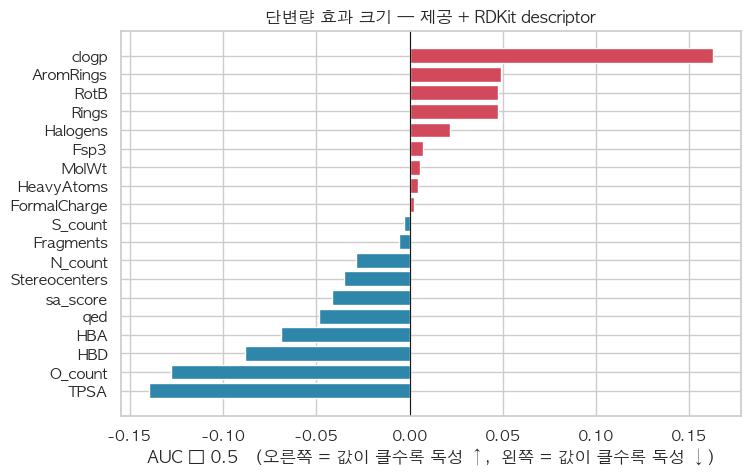

In [7]:
uni_extra = univariate_table(df, extra_cols)
display(uni_extra.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = univariate_table(df, desc_cols + extra_cols).sort_values("AUC(독성↑)")
colors = ["#d1495b" if v > 0.5 else "#2e86ab" for v in plot_df["AUC(독성↑)"]]
ax.barh(plot_df["feature"], plot_df["AUC(독성↑)"] - 0.5, color=colors)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("AUC − 0.5   (오른쪽 = 값이 클수록 독성 ↑,  왼쪽 = 값이 클수록 독성 ↓)")
ax.set_title("단변량 효과 크기 — 제공 + RDKit descriptor")
plt.show()

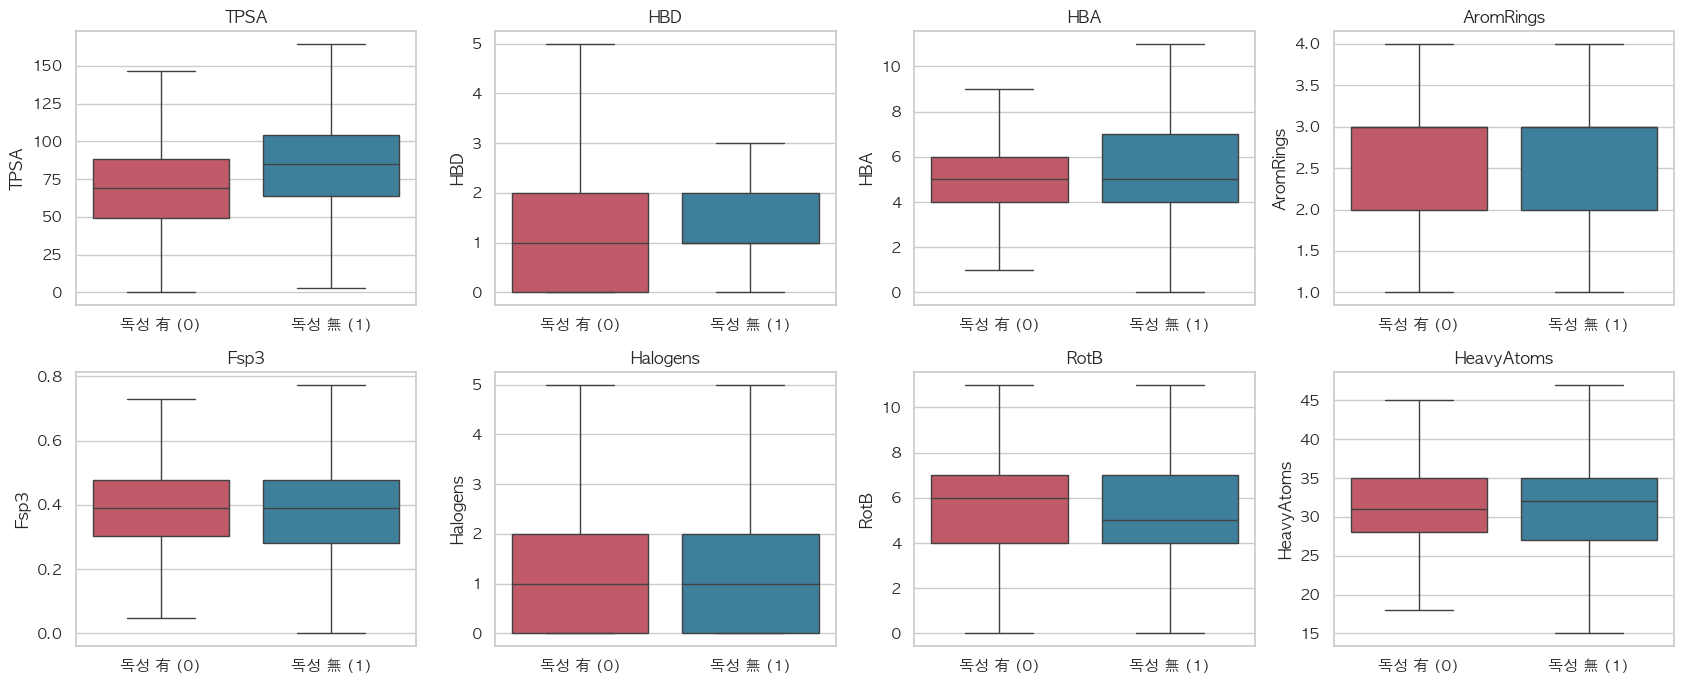

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.flat, ["TPSA", "HBD", "HBA", "AromRings", "Fsp3", "Halogens", "RotB", "HeavyAtoms"]):
    sns.boxplot(data=df, x="label", y=c, hue="label", palette=PALETTE, showfliers=False, legend=False, ax=ax)
    ax.set_xticklabels([LABEL_NAME[0], LABEL_NAME[1]])
    ax.set_xlabel("")
    ax.set_title(c)
plt.tight_layout()
plt.show()

- RDKit 추가 descriptor 중 **TPSA(AUC 0.36)** 와 **산소 원자 수(0.37)**, HBD·HBA가 독성↓ 방향으로 뚜렷하다 → *극성이 높을수록 비독성*.
- 크기 관련 변수(HeavyAtoms, MolWt)와 Fsp3는 거의 무관하다. 즉 이 데이터의 독성 차이는 **크기가 아니라 지용성–극성 균형**에서 온다.

## 5. 의약화학 경험 규칙 검증

| 규칙 | 기준 | 의미 |
|---|---|---|
| **Lipinski RO5** | MW ≤ 500, clogP ≤ 5, HBD ≤ 5, HBA ≤ 10 (위반 ≤ 1 허용) | 경구 흡수 가능성 |
| **Veber** | RotB ≤ 10, TPSA ≤ 140 Å² | 경구 생체이용률 |
| **Pfizer 3/75** | clogP > 3 **그리고** TPSA < 75 Å² → 고위험 | 생체 내 독성 소견 가능성 ≈ 2.5배 (Hughes 2008) |

각 그룹의 독성률과 **χ² 독립성 검정**으로 규칙이 이 데이터에서도 유효한지 확인한다.

In [9]:
df["lipinski_viol"] = ((df["MolWt"] > 500).astype(int) + (df["clogp"] > 5) + (df["HBD"] > 5) + (df["HBA"] > 10))
df["veber_pass"] = (df["RotB"] <= 10) & (df["TPSA"] <= 140)
df["pfizer_zone"] = np.select(
    [(df["clogp"] > 3) & (df["TPSA"] < 75), (df["clogp"] <= 3) & (df["TPSA"] >= 75)],
    ["고위험 (clogP>3, TPSA<75)", "저위험 (clogP≤3, TPSA≥75)"], default="중간",
)

def rate_table(col):
    t = df.groupby(col)["toxic"].agg(n="size", 독성률="mean")
    t["lift(÷기저)"] = t["독성률"] / BASE_TOX
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[col], df["toxic"]))
    return t.round(3), p

for col in ["lipinski_viol", "veber_pass", "pfizer_zone"]:
    t, p = rate_table(col)
    print(f"\n[{col}]  χ² p-value = {p:.2e}")
    display(t)


[lipinski_viol]  χ² p-value = 2.38e-10


,n,독성률,lift(÷기저)
lipinski_viol,,,
0,5652,0.433,0.949
1,1868,0.484,1.061
2,820,0.552,1.212
3,8,0.625,1.371
4,1,0.000,0.000



[veber_pass]  χ² p-value = 6.05e-02


,n,독성률,lift(÷기저)
veber_pass,,,
False,433,0.411,0.902
True,7916,0.458,1.005



[pfizer_zone]  χ² p-value = 4.68e-163


,n,독성률,lift(÷기저)
pfizer_zone,,,
"고위험 (clogP>3, TPSA<75)",3324,0.626,1.372
"저위험 (clogP≤3, TPSA≥75)",1780,0.246,0.540
중간,3245,0.397,0.871


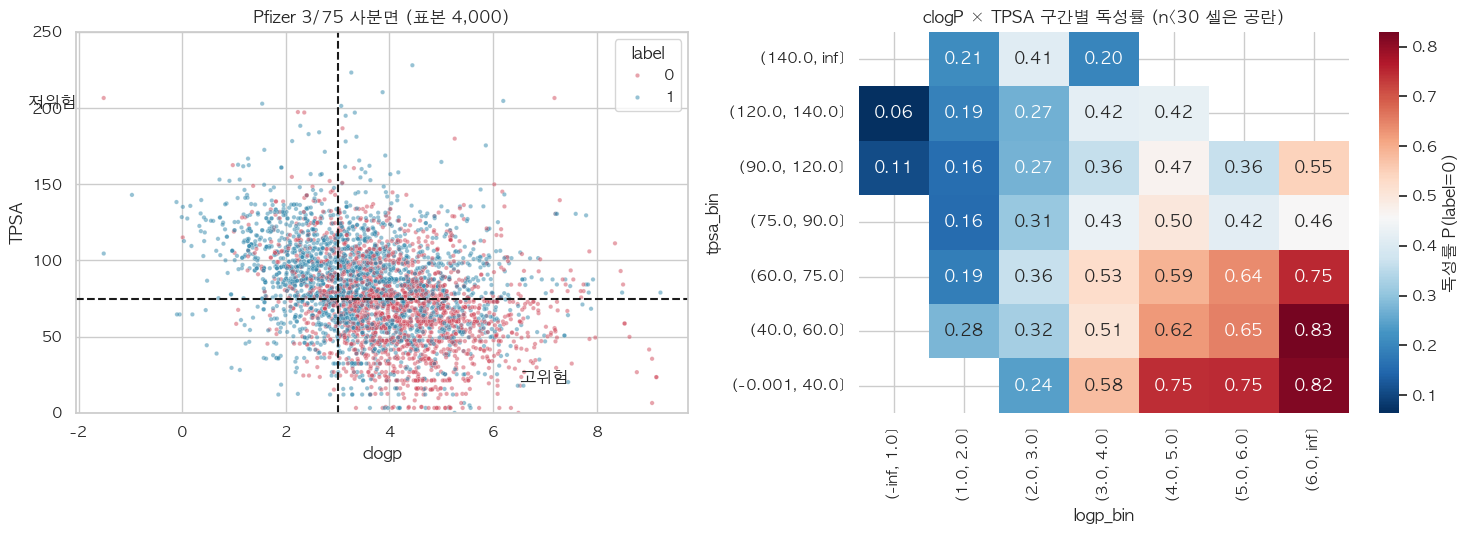

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sample = df.sample(4000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="clogp", y="TPSA", hue="label", palette=PALETTE, s=10, alpha=.5, ax=axes[0])
axes[0].axvline(3, ls="--", c="k"); axes[0].axhline(75, ls="--", c="k")
axes[0].set_ylim(0, 250)
axes[0].set_title("Pfizer 3/75 사분면 (표본 4,000)")
axes[0].text(6.5, 20, "고위험", fontsize=12, weight="bold"); axes[0].text(-3, 200, "저위험", fontsize=12, weight="bold")

grid = df.assign(logp_bin=pd.cut(df["clogp"], [-np.inf, 1, 2, 3, 4, 5, 6, np.inf]),
                 tpsa_bin=pd.cut(df["TPSA"], [0, 40, 60, 75, 90, 120, 140, np.inf], include_lowest=True))
heat = grid.pivot_table(index="tpsa_bin", columns="logp_bin", values="toxic", aggfunc="mean", observed=False)
n = grid.pivot_table(index="tpsa_bin", columns="logp_bin", values="toxic", aggfunc="size", observed=False)
sns.heatmap(heat.where(n >= 30).iloc[::-1], annot=True, fmt=".2f", cmap="RdBu_r", center=BASE_TOX, ax=axes[1],
            cbar_kws={"label": "독성률 P(label=0)"})
axes[1].set_title("clogP × TPSA 구간별 독성률 (n<30 셀은 공란)")
plt.tight_layout()
plt.show()

- **Pfizer 3/75 규칙이 강하게 재현된다:** 고위험 구역 독성률 **62.6%** vs 저위험 구역 **24.6%** (약 **2.5배**, χ² p ≈ 10⁻¹⁶³) — Hughes(2008)의 "약 2.5배"와 거의 같다.
- Lipinski 위반 수가 늘수록 독성률이 증가(0개 43.3% → 2개 55.2%)하지만, Veber 규칙은 유의하지 않다(p = 0.06).
- 히트맵에서도 **오른쪽 아래(고지용성·저극성) 셀일수록 독성률이 높고** 왼쪽 위로 갈수록 낮다.
- 규칙은 단순 이분 기준이므로, 모델에는 규칙 플래그보다 **clogP·TPSA 원값(그리고 상호작용)** 을 넣는 것이 정보 손실이 적다.

## 6. 원소 구성 · 전하 · 다중 성분(염)

일반적인 유기 원소(C, H, N, O, S, P, 할로겐) 외의 원소(금속, B, Si, Se 등)는 독성과 연관되기 쉽고, fingerprint에서는 드문 bit로만 표현되어 학습이 어렵다.
SMILES의 `.`은 염·혼합물(다중 성분)을 뜻한다.

In [11]:
COMMON = {"C", "H", "N", "O", "S", "P", "F", "Cl", "Br", "I"}
df["elements"] = mols.map(lambda m: sorted({a.GetSymbol() for a in m.GetAtoms()}))
df["has_unusual_elem"] = df["elements"].map(lambda e: bool(set(e) - COMMON))

elem_long = df[["elements", "toxic"]].explode("elements")
elem_rate = (elem_long.groupby("elements")["toxic"].agg(n="size", 독성률="mean")
             .query("n >= 10").sort_values("n", ascending=False))
elem_rate["lift"] = elem_rate["독성률"] / BASE_TOX
display(elem_rate.round(3).T)

for col in ["has_unusual_elem", "Fragments", "FormalCharge"]:
    t = df.groupby(df[col].clip(upper=3) if col == "Fragments" else df[col].clip(-2, 2) if col == "FormalCharge" else df[col])["toxic"]
    print(f"\n[{col}]"); display(t.agg(n="size", 독성률="mean").round(3).T)

unusual = sorted(set(elem_long["elements"].dropna()) - COMMON)
print("비일반 원소 목록:", unusual)

elements,C,N,O,F,S,Cl,Br,P
n,8349.000,8288.000,7682.000,3345.000,2126.000,1871.000,169.000,18.000
독성률,0.456,0.458,0.441,0.454,0.448,0.499,0.521,0.056
lift,1.000,1.005,0.968,0.995,0.983,1.094,1.142,0.122



[has_unusual_elem]


has_unusual_elem,False,True
n,8340.000,9.000
독성률,0.456,0.111



[Fragments]


Fragments,1,2,3
n,8087.000,237.000,25.0
독성률,0.459,0.338,0.6



[FormalCharge]


FormalCharge,0,1
n,8315.000,34.000
독성률,0.455,0.765


비일반 원소 목록: ['Na', 'Se', 'Si']


- 비일반 원소(Na, Se, Si)는 9건뿐이라 별도 처리 가치가 작다. **P 포함 화합물(n=18)은 독성률 5.6%** 로 매우 낮다.
- **양전하(+1) 화합물(n=34)은 독성률 76.5%** — 4급 암모늄 등 양이온성 구조. Cl·Br 포함 시 독성률이 소폭 상승(lift 1.09~1.14).
- 다중 성분(염) 화합물은 237+건으로 적고, 염 형태가 fingerprint에 섞여 들어가므로 **최대 성분만 남기는 표준화(salt stripping)** 를 검토할 수 있다.

## 7. 구조 경고(Structural Alerts) — Brenk · PAINS · NIH

RDKit `FilterCatalog`에 내장된 경고 부분 구조를 매칭한다.
- **Brenk (105개):** 반응성·대사 불안정·독성 우려 부분 구조 (예: Michael acceptor, 니트로, 아조, 알킬 할라이드)
- **PAINS (480개):** HTS에서 위양성을 자주 내는 간섭 구조
- **NIH:** 반응성·바람직하지 않은 작용기

경고는 *주의 신호*이지 독성의 확정이 아니므로, **경고별 독성률(lift)** 로 이 데이터에서의 실제 연관성을 확인한다.

,catalog,경고 보유 비율,독성률 | 경고 있음,독성률 | 경고 없음,χ² p
0,BRENK,0.2436,0.5084,0.4391,0.0000
1,PAINS,0.0241,0.5871,0.4527,0.0002
2,NIH,0.0378,0.2911,0.4625,0.0000


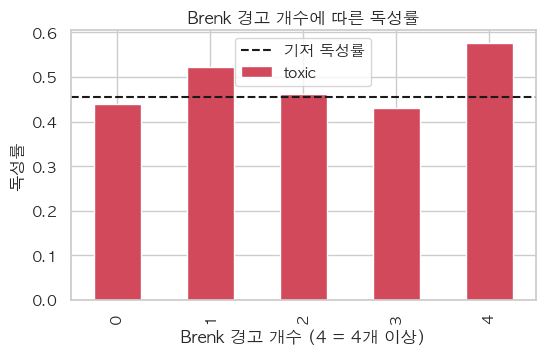

In [12]:
catalogs = {}
for name in ["BRENK", "PAINS", "NIH"]:
    params = FilterCatalogParams()
    params.AddCatalog(getattr(FilterCatalogParams.FilterCatalogs, name))
    catalogs[name] = FilterCatalog(params)

alert_hits = {name: mols.map(lambda m, c=cat: sorted({e.GetDescription() for e in c.GetMatches(m)}))
              for name, cat in catalogs.items()}

summary = []
for name, hits in alert_hits.items():
    df[f"n_{name.lower()}"] = hits.map(len)
    flag = df[f"n_{name.lower()}"] > 0
    summary.append({"catalog": name, "경고 보유 비율": flag.mean(),
                    "독성률 | 경고 있음": df.loc[flag, "toxic"].mean(),
                    "독성률 | 경고 없음": df.loc[~flag, "toxic"].mean(),
                    "χ² p": stats.chi2_contingency(pd.crosstab(flag, df["toxic"]))[1]})
display(pd.DataFrame(summary).round(4))

fig, ax = plt.subplots(figsize=(6, 3.5))
df.groupby(df["n_brenk"].clip(upper=4))["toxic"].mean().plot.bar(ax=ax, color="#d1495b")
ax.axhline(BASE_TOX, ls="--", c="k", label="기저 독성률")
ax.set_xlabel("Brenk 경고 개수 (4 = 4개 이상)"); ax.set_ylabel("독성률"); ax.legend()
ax.set_title("Brenk 경고 개수에 따른 독성률")
plt.show()

In [13]:
rows = []
for name, hits in alert_hits.items():
    exploded = pd.DataFrame({"alert": hits, "toxic": df["toxic"]}).explode("alert").dropna()
    g = exploded.groupby("alert")["toxic"].agg(n="size", 독성률="mean").reset_index()
    g.insert(0, "catalog", name)
    rows.append(g)
alerts = pd.concat(rows).query("n >= 30")
alerts["lift"] = alerts["독성률"] / BASE_TOX
alerts["p_binom"] = [stats.binomtest(int(r.n * r.독성률), int(r.n), BASE_TOX).pvalue for r in alerts.itertuples()]

print("▶ 독성률이 가장 높은 경고 (n ≥ 30)")
display(alerts.sort_values("lift", ascending=False).head(15).round(4))
print("▶ 독성률이 가장 낮은 경고 (n ≥ 30) — 경고지만 이 데이터에서는 오히려 비독성 쪽")
display(alerts.sort_values("lift").head(10).round(4))

▶ 독성률이 가장 높은 경고 (n ≥ 30)


,catalog,alert,n,독성률,lift,p_binom
39,BRENK,nitro_group,53,0.6981,1.5310,0.0005
46,BRENK,quaternary_nitrogen_1,54,0.6667,1.4620,0.0024
2,BRENK,Aliphatic_long_chain,966,0.6470,1.4189,0.0000
13,PAINS,indol_3yl_alk(461),85,0.6353,1.3932,0.0010
38,BRENK,isolated_alkene,92,0.5435,1.1919,0.0949
55,BRENK,triple_bond,144,0.5278,1.1575,0.0941
1,PAINS,anil_di_alk_A(478),41,0.5122,1.1233,0.5316
35,BRENK,imine_1,135,0.5037,1.1047,0.2998
32,BRENK,hydantoin,46,0.5000,1.0965,0.5575
8,BRENK,Oxygen-nitrogen_single_bond,196,0.4439,0.9735,0.7744


▶ 독성률이 가장 낮은 경고 (n ≥ 30) — 경고지만 이 데이터에서는 오히려 비독성 쪽


,catalog,alert,n,독성률,lift,p_binom
16,BRENK,aldehyde,47,0.1702,0.3733,0.0001
28,BRENK,halogenated_ring_1,45,0.1778,0.3899,0.0001
13,NIH,cyanohydrin,41,0.1951,0.4279,0.0008
35,NIH,trifluoroacetate_ester,42,0.2143,0.4699,0.0017
34,BRENK,hydroxamic_acid,104,0.2596,0.5694,0.0000
23,NIH,hydroxamate_warhead,91,0.2747,0.6025,0.0005
4,BRENK,Michael_acceptor_1,154,0.2792,0.6123,0.0000
24,NIH,keto_def_heterocycle,32,0.3750,0.8224,0.3810
18,BRENK,aniline,72,0.4028,0.8833,0.4083
0,BRENK,2-halo_pyridine,138,0.4130,0.9058,0.3473


- Brenk 경고 보유 화합물(24.4%)의 독성률은 50.8%로 미보유(43.9%)보다 높고, PAINS도 58.7%로 높다. 반면 **NIH 경고는 오히려 독성률 29.1%** 로 낮다.
- 경고별로 보면 **nitro group(69.8%)**, **4급 질소(66.7%)**, **긴 지방족 사슬(64.7%, n=966)** 이 독성 쪽이고, **aldehyde·hydroxamic acid·Michael acceptor**는 이 데이터에서 오히려 비독성 쪽이다.
- 즉 일반적인 경고 목록은 *이 데이터의 독성 정의(라벨이 무엇을 측정했는지)* 와 완전히 일치하지 않는다. 경고 개수 하나보다 **주요 경고를 개별 플래그**로 쓰는 것이 낫다.

## 8. 작용기(Functional Group) 기반 분석

RDKit의 `fr_*` descriptor 85종은 SMARTS로 정의된 작용기 개수를 센다. 보유 여부별 독성률 lift를 비교한다.

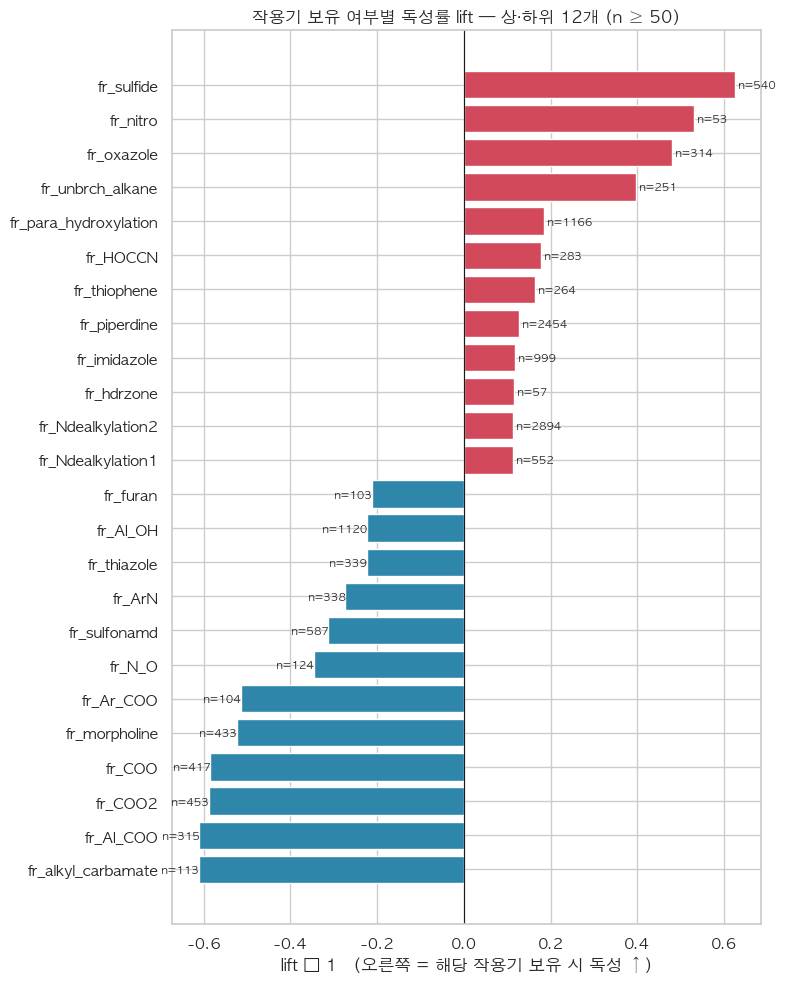

In [14]:
fr_funcs = [(n, f) for n, f in Descriptors.descList if n.startswith("fr_")]
fr = pd.DataFrame({n: mols.map(f) for n, f in fr_funcs})
fr_present = (fr > 0)

fg = pd.DataFrame({
    "n": fr_present.sum(),
    "독성률": [df.loc[fr_present[c], "toxic"].mean() for c in fr_present],
}).query("n >= 50")
fg["lift"] = fg["독성률"] / BASE_TOX
fg = fg.sort_values("lift")

fig, ax = plt.subplots(figsize=(8, 10))
show = pd.concat([fg.head(12), fg.tail(12)])
ax.barh(show.index, show["lift"] - 1, color=["#2e86ab" if v < 1 else "#d1495b" for v in show["lift"]])
for y, (v, n) in enumerate(zip(show["lift"], show["n"])):
    ax.text(v - 1, y, f" n={n}", va="center", ha="left" if v > 1 else "right", fontsize=8)
ax.axvline(0, c="k", lw=.8)
ax.set_xlabel("lift − 1   (오른쪽 = 해당 작용기 보유 시 독성 ↑)")
ax.set_title("작용기 보유 여부별 독성률 lift — 상·하위 12개 (n ≥ 50)")
plt.tight_layout()
plt.show()

## 9. 독성과 연관된 Fingerprint bit의 부분 구조 해석

2장에서 ECFP를 재현했으므로, 각 bit를 켜는 **원자 환경(중심 원자 + 반경)** 을 역추적할 수 있다.
bit별로 **Fisher 정확 검정**과 log-odds ratio를 계산하고(출현율 1%~95%), 상위 bit의 대표 부분 구조를 그린다.

> 1,024bit로 접는(folding) 과정에서 서로 다른 부분 구조가 같은 bit에 충돌할 수 있으므로, bit마다 **가장 자주 나타나는 부분 구조**를 대표로 표시한다.

In [15]:
from collections import Counter, defaultdict

def bit_stats(cols):
    X = df[cols].to_numpy().astype(bool)
    y = df["toxic"].to_numpy().astype(bool)
    on_tox, on_all = (X & y[:, None]).sum(0), X.sum(0)
    out = pd.DataFrame({"bit": range(len(cols)), "support": on_all / len(df),
                        "독성률|bit=1": np.where(on_all > 0, on_tox / np.maximum(on_all, 1), np.nan)})
    a, b = on_tox + .5, on_all - on_tox + .5
    c, d = y.sum() - on_tox + .5, (~y).sum() - (on_all - on_tox) + .5
    out["log_OR"] = np.log((a * d) / (b * c))
    out["p_fisher"] = [stats.fisher_exact([[int(a_ - .5), int(b_ - .5)], [int(c_ - .5), int(d_ - .5)]])[1]
                       for a_, b_, c_, d_ in zip(a, b, c, d)]
    return out[out["support"].between(0.01, 0.95)]      # 거의 모든 분자에 켜진 bit는 해석 가치가 낮아 제외

ecfp_stats = bit_stats(fp_cols["ecfp"])

# bit → 대표 부분 구조 SMILES
ao = rfg.AdditionalOutput(); ao.AllocateBitInfoMap()
bit_frags, bit_example = defaultdict(Counter), {}
for idx, m in mols.items():
    ecfp_gen.GetFingerprint(m, additionalOutput=ao)
    for bit, envs in ao.GetBitInfoMap().items():
        atom, radius = envs[0]
        if radius == 0:
            frag = m.GetAtomWithIdx(atom).GetSymbol() + ("(arom)" if m.GetAtomWithIdx(atom).GetIsAromatic() else "")
        else:
            env = Chem.FindAtomEnvironmentOfRadiusN(m, radius, atom)
            amap = {}
            frag = Chem.MolToSmiles(Chem.PathToSubmol(m, env, atomMap=amap), canonical=True)
        bit_frags[bit][frag] += 1
        if (bit, frag) not in bit_example:
            bit_example[(bit, frag)] = (idx, dict(ao.GetBitInfoMap()))

def describe(bit):
    frag, cnt = bit_frags[bit].most_common(1)[0]
    return frag, cnt / sum(bit_frags[bit].values())

for frame in [ecfp_stats]:
    frame[["대표_부분구조", "대표비중"]] = frame["bit"].map(describe).apply(pd.Series)

top_tox = ecfp_stats.sort_values("log_OR", ascending=False).head(12)
top_safe = ecfp_stats.sort_values("log_OR").head(12)
print("▶ 독성(label=0)과 연관된 ECFP bit"); display(top_tox.round(4))
print("▶ 비독성(label=1)과 연관된 ECFP bit"); display(top_safe.round(4))

▶ 독성(label=0)과 연관된 ECFP bit


,bit,support,독성률|bit=1,log_OR,p_fisher,대표_부분구조,대표비중
425,425,0.0545,0.8066,1.6820,0.0,cnnc(n)S,0.7297
765,765,0.0568,0.7743,1.4833,0.0,CCSc(n)n,0.6920
158,158,0.0635,0.7509,1.3585,0.0,CCS,0.6472
826,826,0.0113,0.7447,1.2467,0.0,cc(n)-c(nn)n(c)C,0.4043
450,450,0.0175,0.7397,1.2330,0.0,CCC(CC)(CC)OC,0.7055
355,355,0.0562,0.7228,1.1968,0.0,cn(C)c(nn)SC,0.6994
116,116,0.0819,0.7047,1.1346,0.0,S,0.6155
91,91,0.0171,0.7203,1.1334,0.0,[C@][C@H](C)c(cc)cc,0.2937
295,295,0.0314,0.6985,1.0447,0.0,cnc(C)c(-c)o,0.4008
957,957,0.0156,0.7000,1.0321,0.0,CCN(C)C,0.5308


▶ 비독성(label=1)과 연관된 ECFP bit


,bit,support,독성률|bit=1,log_OR,p_fisher,대표_부분구조,대표비중
663,663,0.0246,0.1317,-1.7268,0.0,cn(c)CCN,0.4098
553,553,0.0253,0.1422,-1.6398,0.0,CC(C)OC(C)C,0.5782
308,308,0.0250,0.1531,-1.5525,0.0,CC(C)O,0.6077
860,860,0.0261,0.1651,-1.4643,0.0,[C@H]NC,0.3945
897,897,0.0240,0.1650,-1.4617,0.0,COC,0.6250
712,712,0.0285,0.1765,-1.3877,0.0,cncc(c)C,0.3571
115,115,0.0217,0.1934,-1.2644,0.0,cNC(=O)[C@H](C)O,0.2707
313,313,0.0145,0.2066,-1.1691,0.0,[C@][C@H](C)C[C@H](C)N,0.4132
982,982,0.0195,0.2209,-1.0932,0.0,cnc(cn)NC,0.2945
937,937,0.0337,0.2242,-1.0917,0.0,COC,0.2349


▶ 독성 연관 ECFP bit의 원자 환경 (파랑 = 중심 원자, 노랑 = 방향족 원자)


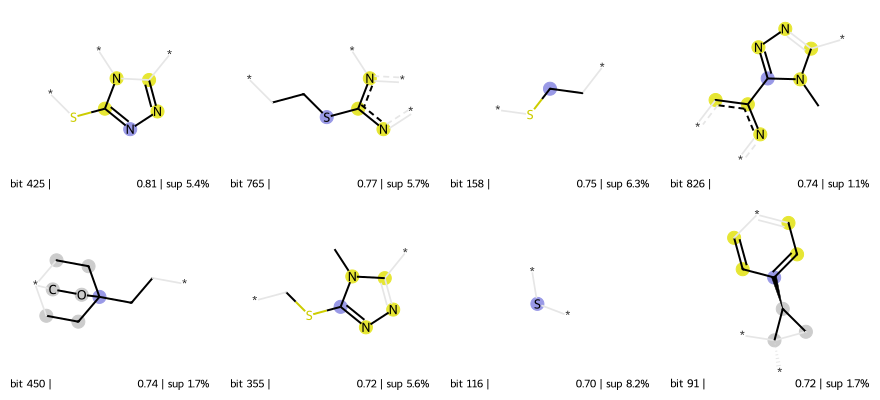

▶ 비독성 연관 ECFP bit의 원자 환경


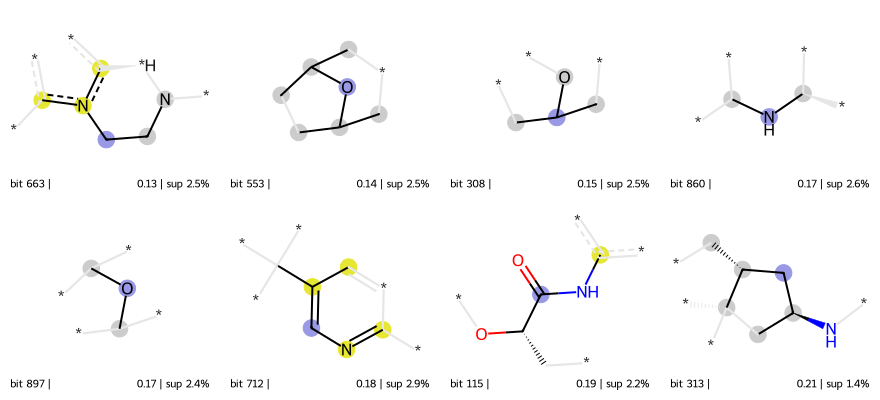

In [16]:
def draw_bits(table, title, n=8):
    items, legends = [], []
    for _, r in table.head(n).iterrows():
        bit = int(r["bit"])
        idx, info = bit_example[(bit, r["대표_부분구조"])]
        items.append((mols[idx], bit, info))
        legends.append(f"bit {bit} | 독성률 {r['독성률|bit=1']:.2f} | sup {r['support']:.1%}")
    print(title)
    return Draw.DrawMorganBits(items, molsPerRow=4, legends=legends, subImgSize=(220, 200))

display(draw_bits(top_tox, "▶ 독성 연관 ECFP bit의 원자 환경 (파랑 = 중심 원자, 노랑 = 방향족 원자)"))
display(draw_bits(top_safe, "▶ 비독성 연관 ECFP bit의 원자 환경"))

In [17]:
# PTFP는 도메인 서브구조 패턴 기반 → 블록별 유의 bit 수 비교
sig = []
for k, cols in fp_cols.items():
    s = bit_stats(cols)
    sig.append({"fingerprint": k.upper(), "출현율 1~95% bit": len(s),
                "Bonferroni 유의 bit (p<0.05/1024)": int((s["p_fisher"] < 0.05 / 1024).sum()),
                "|log OR| 상위 20 평균": s["log_OR"].abs().nlargest(20).mean()})
display(pd.DataFrame(sig).round(3))

,fingerprint,출현율 1~95% bit,Bonferroni 유의 bit (p<0.05/1024),|log OR| 상위 20 평균
0,ECFP,924,169,1.321
1,FCFP,599,153,1.625
2,PTFP,769,182,1.187


- 독성 쪽 상위 bit에는 **S-알킬 트리아졸(`cnnc(n)S`, `CCSc(n)n`, `cn(C)c(nn)SC`)과 티오에테르(`CCS`)** 가 반복된다. 출현율 5~6%에서 독성률 72~81%로, 특정 **화학 시리즈**가 독성 라벨에 몰려 있을 가능성이 크다(10장 scaffold 표에서도 `CCCSc…nnc…[nH]` 계열이 독성률 100%).
- 비독성 쪽에는 **에테르·알코올(`COC`, `CC(C)O`), 키랄 아민/아마이드, Boc 카바메이트**처럼 극성 산소·질소 환경이 많다 — 5장의 *극성↑ → 비독성* 결과와 일관된다.
- Bonferroni 유의 bit 수는 PTFP(182) > ECFP(169) > FCFP(153)이고, 상위 20개 bit의 평균 |log OR|은 FCFP(1.63)가 가장 크다. 세 fingerprint가 **서로 보완적**이다.

## 10. 골격(Bemis–Murcko Scaffold) 다양성

같은 골격의 유사체가 train/validation에 동시에 들어가면 성능이 과대평가된다. 골격 수준의 다양성과 라벨 순도를 확인한다.

고유 scaffold: 4,160개  (화합물 대비 49.8%)
단일 화합물 scaffold(singleton): 2,896개
n≥5 scaffold 330개의 라벨 순도 평균: 0.831  (1.0 = scaffold 내 라벨 동일)


,n,독성률
scaffold,,
O=C1COc2ccc(CNC34CCC(CCc5ccnc6cccnc56)(CC3)OC4)nc2N1,92,0.870
c1ccc(Oc2ccccc2)cc1,48,0.917
c1ccccc1,44,0.795
C1=C(CN2CCOCC2)NC(c2nccs2)=NC1c1ccccc1,39,0.205
O=C(c1ccccc1)N1CCn2c(nnc2-c2ncns2)C1,38,0.000
c1ccc(C2CCc3ccc4[nH]cnc4c3O2)cc1,31,0.258
C1=C(c2ccccc2)c2ccccc2OC12CCNCC2,29,0.586
c1ccc(C23CC2CN(CCCSc2nnc(-c4cnco4)[nH]2)C3)cc1,29,1.000
c1ccc(CCN2CCC(CN3CCC(Oc4ccccc4)CC3)CC2)cc1,26,0.231


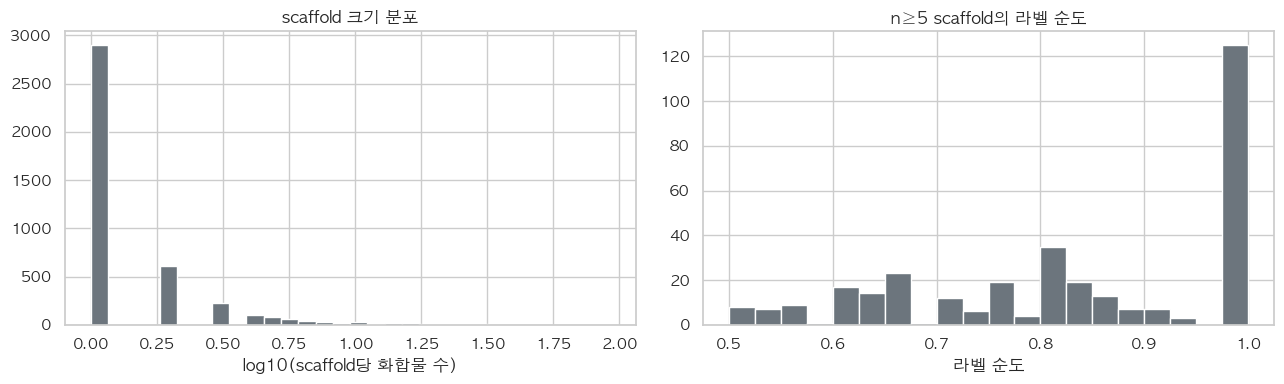

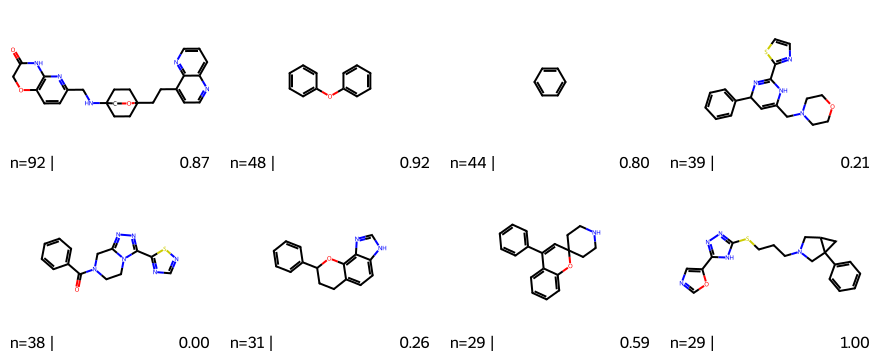

In [18]:
df["scaffold"] = mols.map(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m))
df.loc[df["scaffold"] == "", "scaffold"] = "(비고리 화합물)"
scaf = df.groupby("scaffold")["toxic"].agg(n="size", 독성률="mean").sort_values("n", ascending=False)

print(f"고유 scaffold: {len(scaf):,}개  (화합물 대비 {len(scaf) / len(df):.1%})")
print(f"단일 화합물 scaffold(singleton): {(scaf['n'] == 1).sum():,}개")
multi = scaf[scaf["n"] >= 5]
purity = np.maximum(multi["독성률"], 1 - multi["독성률"])
print(f"n≥5 scaffold {len(multi)}개의 라벨 순도 평균: {purity.mean():.3f}  (1.0 = scaffold 내 라벨 동일)")
display(scaf.head(12).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(scaf["n"]), bins=30, color="#6c757d")
axes[0].set_xlabel("log10(scaffold당 화합물 수)"); axes[0].set_title("scaffold 크기 분포")
axes[1].hist(purity, bins=20, color="#6c757d")
axes[1].set_xlabel("라벨 순도"); axes[1].set_title("n≥5 scaffold의 라벨 순도")
plt.tight_layout(); plt.show()

top_scaf = [s for s in scaf.index[:8] if s != "(비고리 화합물)"]
display(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in top_scaf], molsPerRow=4, subImgSize=(220, 180),
                             legends=[f"n={scaf.loc[s, 'n']} | 독성률 {scaf.loc[s, '독성률']:.2f}" for s in top_scaf]))

- 고유 scaffold **4,160개(화합물의 49.8%)**, 그중 2,896개는 화합물 1개뿐 → 구조적으로 매우 다양하다.
- 반면 n ≥ 5인 scaffold의 **라벨 순도는 평균 0.83**이고, 여러 대형 시리즈가 독성률 0% 또는 100%이다. 같은 골격 유사체가 train/valid에 나뉘면 **골격 암기로 성능이 과대평가**된다.

## 11. 피처 묶음별 예측 신호 점검 (Baseline)

본격 모델링 전, **어떤 피처 묶음에 신호가 많은지**를 빠르게 비교한다. 두 가지 분할을 비교한다.
- **Stratified 5-fold:** 무작위 분할
- **Scaffold Group 5-fold:** 같은 scaffold는 같은 fold → 새로운 골격에 대한 일반화 성능

두 점수의 차이가 크면 모델이 *골격 암기*에 의존한다는 뜻이다.

,피처,n_features,AUC random,AUC scaffold,차이
0,제공 descriptor 4,4,0.7408,0.6826,0.0583
1,+ RDKit descriptor,22,0.8423,0.7893,0.0530
2,ECFP,1024,0.8594,0.8102,0.0492
3,FCFP,1024,0.8653,0.8149,0.0503
4,PTFP,1024,0.8524,0.7915,0.0609
5,ECFP+FCFP+PTFP+desc,3091,0.8785,0.8345,0.0440


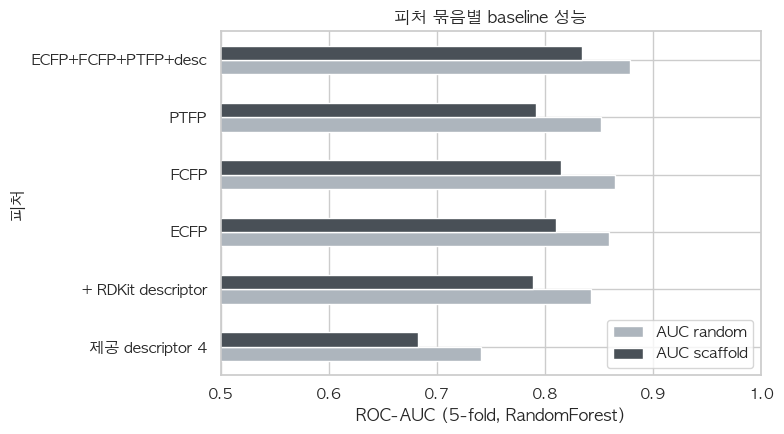

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

y = df["label"]
groups = df["scaffold"]
feature_sets = {
    "제공 descriptor 4": desc_cols,
    "+ RDKit descriptor": desc_cols + extra_cols + ["n_brenk", "n_pains", "n_nih"],
    "ECFP": fp_cols["ecfp"],
    "FCFP": fp_cols["fcfp"],
    "PTFP": fp_cols["ptfp"],
    "ECFP+FCFP+PTFP+desc": sum(fp_cols.values(), []) + desc_cols + extra_cols,
}
cv_random = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_scaffold = StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)

results = []
for name, cols in feature_sets.items():
    X = df[cols].astype(np.float32)
    r = cross_val_score(rf, X, y, cv=cv_random, scoring="roc_auc", n_jobs=1)
    s = cross_val_score(rf, X, y, cv=cv_scaffold, groups=groups, scoring="roc_auc", n_jobs=1)
    results.append({"피처": name, "n_features": len(cols),
                    "AUC random": r.mean(), "AUC scaffold": s.mean(), "차이": r.mean() - s.mean()})
res = pd.DataFrame(results)
display(res.round(4))

ax = res.set_index("피처")[["AUC random", "AUC scaffold"]].plot.barh(figsize=(8, 4.5), color=["#adb5bd", "#495057"])
ax.set_xlim(0.5, 1); ax.set_xlabel("ROC-AUC (5-fold, RandomForest)")
ax.set_title("피처 묶음별 baseline 성능")
plt.tight_layout(); plt.show()

- 모든 피처 묶음에서 scaffold CV가 random CV보다 **AUC 0.04~0.06 낮다** → 실제 신규 골격에 대한 성능은 random CV보다 낮게 기대해야 한다.
- 제공 descriptor 4개(AUC 0.74)에 **RDKit descriptor 18개를 더하면 0.84**로 크게 오르며, 단일 fingerprint(0.85~0.87)에 근접한다.
- 전체 결합 시 random 0.879 / scaffold 0.835로 가장 높다. 단일 fingerprint 중에는 FCFP가 가장 좋다.

## 12. 결론 및 모델링 시사점

**데이터 품질**
- 결측·중복 SMILES 없음, 라벨 독성 45.6% : 비독성 54.4% → `stratify` 분할이면 충분하다.
- 피처가 **RDKit으로 재현된다**: ECFP4(Morgan r=2, 99.94% 행 일치), FCFP4·PatternFingerprint(100%), MolWt·clogp·qed.
  → `predict_input.csv`의 SMILES만으로 동일 피처와 추가 descriptor를 만들 수 있다.

**도메인 신호**
| 발견 | 근거 |
|---|---|
| 지용성↑ → 독성↑ | clogp AUC 0.66, 중앙값 4.15 vs 3.37 |
| 극성↑ → 독성↓ | TPSA AUC 0.36, O 원자 수 0.37 |
| **Pfizer 3/75 규칙 재현** | 고위험 62.6% vs 저위험 24.6% (≈ 2.5배) |
| 분자 크기는 무관 | MolWt AUC 0.505 |
| 구조 경고는 방향이 제각각 | nitro·4급 질소·긴 지방족 사슬 ↑ / aldehyde·hydroxamic acid ↓ |
| 화학 시리즈 효과 | S-알킬 트리아졸 bit 독성률 72~81%, n≥5 scaffold 라벨 순도 0.83 |

**모델링 전략 제안**
1. **피처:** `ECFP + FCFP + PTFP` + 제공 descriptor + RDKit 추가 descriptor(TPSA, O/N 수, HBD/HBA, 방향족 고리, RotB, 전하) + 주요 구조 경고 플래그 + Pfizer 구역(또는 clogP×TPSA 상호작용)
2. **전처리:** 상수 bit 제거, (선택) salt stripping 후 피처 재계산, 선형 모델 사용 시 descriptor 스케일링
3. **검증:** random CV와 **Scaffold Group CV를 함께 보고**, 하이퍼파라미터·모델 선택은 scaffold CV 기준
4. **모델 후보:** RandomForest(baseline AUC 0.88/0.83) → LightGBM·XGBoost(희소 이진 피처에 강함) → 확장 시 GNN·ChemBERTa 등 SMILES 기반 모델
5. **평가:** PDF p.15 기준 Accuracy·Precision·Recall·F1·ROC-AUC — **Positive = label 1(독성 無)** 임에 유의. 신약 스크리닝에서는 독성 물질을 비독성으로 통과시키는 비용이 크므로 **specificity(label 0을 0으로 맞히는 비율)** 를 함께 보고, 필요하면 분류 임계값을 조정한다.

**한계**
- 라벨이 어떤 독성 시험(급성·간독성·hERG 등)에서 왔는지 알 수 없어, 문헌의 구조 경고와 방향이 다른 경우의 원인을 확정할 수 없다.
- 단변량·연관 분석은 인과관계를 의미하지 않으며, 화학 시리즈 효과가 혼재되어 있다.